In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("inventory.db")

df = pd.read_sql_query("SELECT * FROM country_analysis", conn)
print(df.head(10))

DatabaseError: Execution failed on sql 'SELECT * FROM country_analysis': no such table: country_analysis

In [29]:
obj=pd.read_sql_query("""SELECT
                         [country],
                         [Quality Of Life Index],
                         [Exports of goods and services (% of GDP)],
                         [Purchasing Power Index],
                         [govt_type] 
                         FROM country_analysis
                         WHERE  [govt_type] IN("Federal Republic", "One-Party State", "Republic", "Federal Parliamentary Constitutional Monarchy", "Constitutional Monarchy")
                           """,conn)
print(obj.head(5))

     country  Quality Of Life Index  Exports of goods and services (% of GDP)  \
0      India                 101.52                                 18.782685   
1      China                  90.95                                 19.692278   
2  Indonesia                  62.02                                 20.177304   
3  Australia                 176.54                                 21.193200   
4  Sri Lanka                  88.99                                 21.831465   

   Purchasing Power Index                                      govt_type  
0                   76.73                               Federal Republic  
1                   67.84                                One-Party State  
2                   27.61                                       Republic  
3                  101.94  Federal Parliamentary Constitutional Monarchy  
4                   30.28                                       Republic  


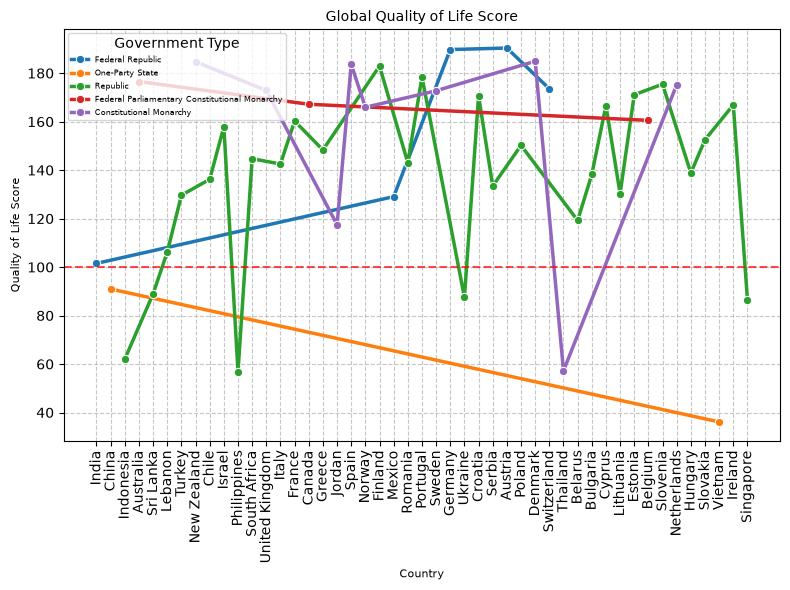

In [33]:
plt.figure(figsize=(8, 6), dpi=100)
sns.lineplot(x='country', y='Quality Of Life Index', data=obj ,hue='govt_type', marker='o', linewidth=2.5, color="#35b41f")
plt.title('Global Quality of Life Score', fontsize=10)
plt.xlabel('Country', fontsize=8)
plt.ylabel('Quality of Life Score', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(obj['country'],rotation=90)

#ad values to the points on the line plot
#for y, x in zip(df['govt_type'], df['Quality Of Life Index']):
    #plt.text(y + 0.02, x, f'{y:.3f}', ha='left', fontsize=10)

# Add vertical line 
plt.axhline(y=100, color='red', linestyle='--', alpha=0.7,)
plt.legend(title='Government Type', fontsize=6, title_fontsize=10, loc='upper left')
plt.tight_layout()
#plt.savefig(r'C:\Users\jitip\inventory analytics\quality-of-life-indexi.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
subj=pd.read_sql_query("""SELECT
                         [country],
                         [Quality Of Life Index],
                         [Exports of goods and services (% of GDP)],
                         [Purchasing Power Index],
                         [govt_type] 
                         FROM country_analysis
                         WHERE [Quality Of Life Index]<="101.52" AND [govt_type]="Federal Republic"
                           """,conn)

In [ ]:
plt.figure(figsize=(8, 6), dpi=100)
sns.lineplot(x='country', y='Quality Of Life Index', data=obj , marker='o', linewidth=2.5, color="#35b41f")
plt.title('Global Quality of Life Score', fontsize=10)
plt.xlabel('Country', fontsize=8)
plt.ylabel('Quality of Life Score', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(obj['country'],rotation=90)

#ad values to the points on the line plot
#for y, x in zip(df['country'], df['Quality Of Life Index']):
    #plt.text(y + 0.02, x, f'{y:.3f}', ha='left', fontsize=10)

# Add vertical line 
plt.axhline(y=100, color='red', linestyle='--', alpha=0.7,)
plt.legend()
plt.tight_layout()
#plt.savefig(r'C:\Users\jitip\inventory analytics\quality-of-life-indexi.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
top10_exports = df.nlargest(10, ['Exports of goods and services (% of GDP)'])
bottom10_exports = df.nsmallest(10, ['Exports of goods and services (% of GDP)'])

# Create side by side bar plots
fig, axes = plt.subplots(1,2,figsize=(10, 7))

# Top 10 countries
sns.barplot(ax=axes[0], y='country', x='Exports of goods and services (% of GDP)', data=top10_exports.sort_values('Exports of goods and services (% of GDP)', ascending=False), 
            palette='viridis')
axes[0].set_title('Top 10 Highest Exporting Countries', fontsize=10)
axes[0].set_xlabel('Exports of Goods and Services (% of GDP)', fontsize=8)
axes[0].set_ylabel('Country', fontsize=12)
axes[0].bar_label(axes[0].containers[0], fmt='%.2f', padding=3)

# Bottom 10 countries
sns.barplot(ax=axes[1], y='country', x='Exports of goods and services (% of GDP)', data=bottom10_exports.sort_values('Exports of goods and services (% of GDP)'), 
            palette='viridis')
axes[1].set_title('Bottom 10  lowest exporting countries', fontsize=10)
axes[1].set_xlabel('Exports of Goods and Services (% of GDP)', fontsize=8)
axes[1].set_ylabel('Country', fontsize=8)
axes[1].bar_label(axes[1].containers[0], fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()


In [ ]:
top10_eduction_focused_countries = df.nlargest(10, ['Education: Government expenditure (% of GDP)'])
bottom10_eduction_focused_countries = df.nsmallest(10, ['Education: Government expenditure (% of GDP)'])

fig, axes=plt.subplots(1,2,figsize=(10,7))

#top_10_countries_education_focused
sns.barplot(ax=axes[0], y='country', x='Education: Government expenditure (% of GDP)', data=top10_eduction_focused_countries.sort_values('Education: Government expenditure (% of GDP)', ascending=False), 
            palette='viridis')
axes[0].set_title('Top 10 with Highest Education Expenditure', fontsize=10)
axes[0].set_xlabel('Education: exp', fontsize=8)
axes[0].set_ylabel('Country', fontsize=8)
axes[0].bar_label(axes[0].containers[0], fmt='%.2f', padding=3)

# # Bottom 10 countries education
sns.barplot(ax=axes[1], y='country', x='Education: Government expenditure (% of GDP)', data=bottom10_eduction_focused_countries.sort_values('Education: Government expenditure (% of GDP)'), 
            palette='viridis')
axes[1].set_title('Bottom 10 countries with lowest Education Expenditure', fontsize=10)
axes[1].set_xlabel('Education: exp', fontsize=8)
axes[1].set_ylabel('Country', fontsize=8)
axes[1].bar_label(axes[1].containers[0], fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

TypeError: can't multiply sequence by non-int of type 'float'

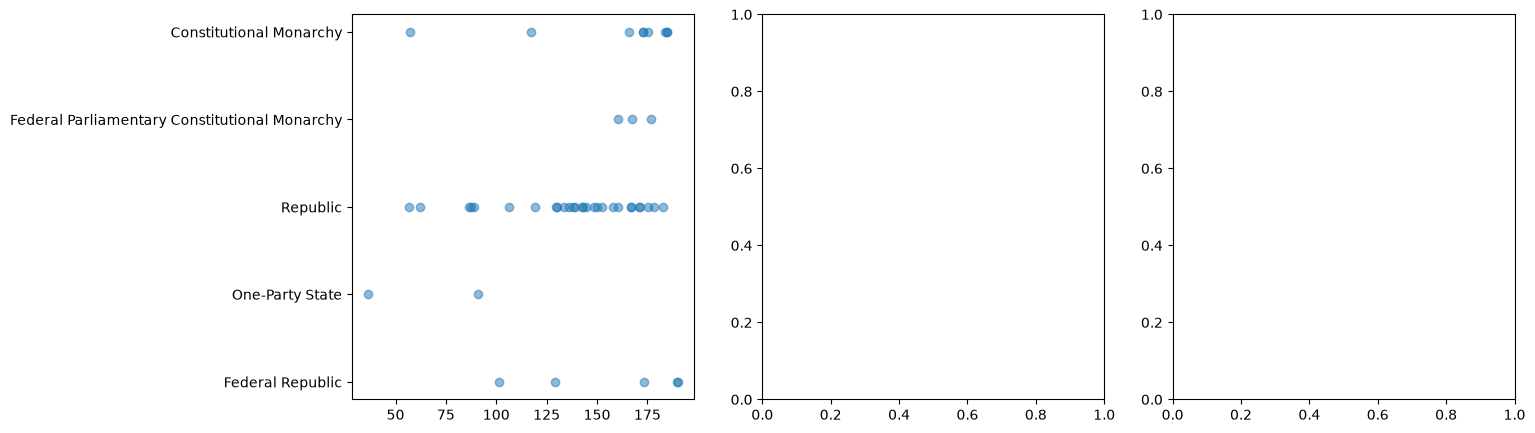

In [34]:
factors = ['govt_type']
fig, axes = plt.subplots(1,3, figsize=(15, 5))
axes = axes.flatten()

for i, factor in enumerate(factors):
    sns.regplot(ax=axes[i], y=factor, x='Quality Of Life Index', data=obj, 
                scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    axes[i].set_title(f'{factor} vs. Quality of Life Index', fontsize=10)
    axes[i].set_ylabel(factor, fontsize=8)
    axes[i].set_xlabel('Quality of Life Index', fontsize=8)
    
    # Add correlation coefficient
    corr = obj[factor].corr(obj['Quality Of Life Index'])
    axes[i].annotate(f'r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', 
                     fontsize=12, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="b", lw=1))

plt.suptitle('Relationship Between Factors and Happiness Score (2024)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()
